# Lab: Relationships Between Categorical Features

Imagine James Cameron has hired you to develop two character profiles for a Titanic movie reboot: one “most likely to survive” and one “least likely to survive.” Support both profiles with passenger data and visualizations, then connect them to real people and their biographies.

These labels describe profiles suggested by observed group survival percentages in this dataset. They are not guaranteed individual outcomes, a validated prediction model, or proof that any feature caused survival.


## Learning goals

- Apply the six-step analysis workflow to categorical comparisons.
- Justify categories created from age and travel-companion counts.
- Distinguish raw counts from survival percentages within groups.
- Build clearly labeled figures and check their meaning.
- Support character profiles with evidence and identify matching passengers.
- Connect data records to cited historical biographies.


## The reproducible analysis workflow

1. **Question:** What do we want to learn?
2. **Data:** Which observations and features can help answer it?
3. **Evidence:** What should we calculate and display to answer the question?
4. **Check:** Does the result make sense in context? Do the original values support the coding and interpretation?
5. **Conclusion:** What claim is supported?
6. **Limitation:** What should we avoid concluding?

Use one six-step workflow for the complete character-profile investigation. All six feature comparisons belong together in Step 3: Evidence.


## Dataset and scope

Use the supplied `data/titanic_passengers.csv`, the 891-row training dataset from [Kaggle Titanic: Machine Learning from Disaster](https://www.kaggle.com/c/titanic/data). Each row represents a passenger in this file; it is not a complete passenger-and-crew list. Consult the source dictionary when interpreting the features.

Analyze only categorical comparisons with `Survived`. Use `Pclass` instead of `Fare`; do not analyze fare. Age is the exception: convert it to justified categories before comparing survival. Treat travel-companion counts as categories, combining sparse groups if appropriate. Use names and passenger IDs only to identify people.

| Feature | Meaning and role |
| --- | --- |
| `Survived` | Categorical outcome: 0 = did not survive, 1 = survived |
| `Pclass` | Ordered passenger class: 1, 2, or 3; categorical despite numeric storage |
| `Sex` | Recorded sex category |
| `Age` | Age in years; use only through your chosen age groups |
| `Parch` | Count of parents/children aboard; use as categories or collapse into groups |
| `SibSp` | Count of siblings/spouse aboard; use as categories or collapse into groups |
| `Embarked` | Embarkation port: C = Cherbourg, Q = Queenstown, S = Southampton |
| `Name`, `PassengerId` | Passenger identification for matching records to biographies |

The file also contains `Ticket`, `Fare`, and `Cabin`; do not use them as comparison features in this lab.


## Using AI tools responsibly

You may use AI for questions, debugging, or feedback. You remain responsible for understanding the code and checking claims against the output. Read the actual Encyclopedia Titanica biographies rather than using an uncited AI-generated fact. Disclose AI use in the final reflection.


## Step 1: Question

**Which categorical characteristics support a “most likely to survive” profile and a “least likely to survive” profile in this Titanic dataset?**

Consider age group, sex, passenger class, parents/children aboard, siblings/spouse aboard, and embarkation port together as parts of this one investigation.


**Before examining survival percentages, describe your predicted high-survival and low-survival profiles. What reasoning or prior knowledge supports your predictions?**

Your answer:I predict women, children, and first-class passengers will have higher survival rates, while adult men in third class will have lower rates, based on my understanding of lifeboat evacuation priorities. I am less certain how family members aboard and embarkation port will relate to survival.


## Step 2: Data


## Load and inspect the data

Use `titanic_df` as the DataFrame name. Keep the original columns so your category choices can be checked.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt


In [2]:
titanic_df = pd.read_csv("data/titanic_passengers.csv")

In [3]:
titanic_df.head()


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [ ]:
titanic_df.info()


In [4]:
titanic_df.isna().sum()


PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

**What does one row represent? Which feature is the target, and what do its codes mean?**

Your answer:One row represents one passenger in this dataset. The target is Survived: 0 means the passenger did not survive, and 1 means the passenger survived


Complete this table from the inspection. Distinguish a feature's meaning from its Pandas storage type; numeric codes can represent categories.


| Feature | Data type (categorical/quantitative/identifier) | Data storage type | Missing values |
| --- | --- | --- | ---: |
| `PassengerId` |identifier  | int64 | 0 |
| `Name` | identifier | str or object | 0 |
| `Survived` | Categorical | int64 | 0 |
| `Pclass` | Categorical | int64 | 0 |
| `Sex` | Categorical | str or object | 0 |
| `Age` | Quantitative | float64 | 177 |
| `Parch` | Quantitative count | int64 | 0 |
| `SibSp` | Quantitative count | int64 | 0 |
| `Embarked` | 	Categorical | int or object | 0 |


## Plan your age groups before comparing survival

Choose your own age categories. You might use children versus adults, split at 16, 18, or 20, or define several groups such as children, teens, young adults, and older adults. There is no single required cutoff. Give a reasoned argument based on the meaning of the groups and their usefulness, not just which split produces the strongest survival difference.

Write exact boundaries, including where an age exactly at a cutoff belongs. Cover all known ages without overlapping groups. Preserve unknown ages as missing or label them “Unknown”; do not accidentally classify them as adults. If you exclude unknown ages from this comparison, state that denominator choice. Do not guess an age from whether someone survived.


| Age-group label | Exact rule (including boundary values) | Reason for this choice |
| --- | --- | --- |
| Under 18 | Age <18 | groups teenagers and children |
| 18 and older | Age ≥18 | Provides an adult comparison; includes exactly 18 |
| unknown | Age is missing | 	Keeps missing ages separate |

Add rows if needed.


**Why are your age groups reasonable? How will you handle unknown ages, and why?**

Your answer:I chose an age cutoff of 18 to compare passengers under 18 with adults. These groups cover all known ages without overlap, and passengers exactly 18 belong to the adult group. I will label missing ages “Unknown” rather than guessing or treating them as adults. Unknown ages will be reported separately and excluded from comparisons specifically between the two known-age groups.


Create `age_group` using `.loc` or `pd.cut`. If using `.loc`, initialize the column to an explicit “Unknown” label and assign labels only where ages satisfy your rules. If using `pd.cut`, choose its interval boundaries carefully and document whether intervals include their right or left endpoint. Count the observations in each category, including unknowns.


In [5]:
titanic_df["age_group"] = "Unknown"

titanic_df.loc[titanic_df["Age"] < 18, "age_group"] = "Under 18"
titanic_df.loc[titanic_df["Age"] >= 18, "age_group"] = "18 and older"

titanic_df["age_group"].value_counts(dropna=False)


age_group
18 and older    601
Unknown         177
Under 18        113
Name: count, dtype: int64

**Are any age groups very small? Would a different grouping be more useful? Explain any revision before comparing survival.**

Your answer:Neither known-age group is extremely small: there are 113 passengers under 18 and 601 aged 18 or older. The groups are unequal in size, so I will compare survival percentages and keep the counts visible for context. I will retain these age groups without revision. The 177 passengers with unknown ages will be reported separately, since assigning them to an age group would require guessing.


### Choose travel-companion categories

Inspect the frequencies of `Parch` and `SibSp`. Treat their values as discrete categories or collapse them into meaningful groups, such as none/any or none/one/two or more. Explain your choices, particularly when some categories have few passengers. Preserve the original columns.


In [6]:
display(titanic_df["Parch"].value_counts(dropna=False).sort_index())
display(titanic_df["SibSp"].value_counts(dropna=False).sort_index())

titanic_df["parch_group"] = "None"
titanic_df.loc[titanic_df["Parch"] > 0, "parch_group"] = "One or more"

titanic_df["sibsp_group"] = "None"
titanic_df.loc[titanic_df["SibSp"] > 0, "sibsp_group"] = "One or more"

titanic_df["embarked_group"] = titanic_df["Embarked"].fillna("Unknown")

display(titanic_df["parch_group"].value_counts())
display(titanic_df["sibsp_group"].value_counts())


Parch
0    678
1    118
2     80
3      5
4      4
5      5
6      1
Name: count, dtype: int64

SibSp
0    608
1    209
2     28
3     16
4     18
5      5
8      7
Name: count, dtype: int64

parch_group
None           678
One or more    213
Name: count, dtype: int64

sibsp_group
None           608
One or more    283
Name: count, dtype: int64

**What travel-companion groups will you use, and why? State any exclusions and how you will handle unknown embarkation ports. Which observations form the denominator for each comparison?**

Your answer:For parents/children aboard, I will compare “None” (678 passengers) with “One or more” (213 passengers). For siblings/spouse aboard, I will compare “None” (608 passengers) with “One or more” (283 passengers). Combining positive counts avoids comparing very small individual-count categories. The original Parch and SibSp columns are preserved.

Missing embarkation ports are labeled “Unknown” and reported separately. No passengers are excluded from the family-companion comparisons. Each survival percentage uses all passengers in that comparison category as its denominator, including survivors and non-survivors. Unknown ages or ports do not exclude passengers from comparisons where their relevant feature is known.


## Step 3: Evidence

Bring all six feature comparisons together here. For each feature:

- Display a count cross-tab with comparison categories in rows and survival outcomes in columns.
- Calculate survival percentages within each comparison group and display only the percentage who survived (column `1`). Keep group counts available for context.
- Make a bar chart of the conditional percentage who survived, with a meaningful title, descriptive axes, readable category labels, and named colors. Use a 0–100 percentage scale and `plt.legend()` if a legend is needed. Move it outside the axes if it covers the data.

Use separate code cells for the individual operations and add cells as needed. The subsections below organize the evidence; they are not separate workflows.


### Age groups

Compare `age_group` with `Survived` using your Data-step choices.


In [8]:
age_counts = pd.crosstab(
    titanic_df["age_group"], titanic_df["Survived"]
).reindex(["Under 18", "18 and older", "Unknown"])

age_counts


Survived,0,1
age_group,,
Under 18,52,61
18 and older,372,229
Unknown,125,52


In [9]:
age_survival_pct = age_counts[1] / age_counts.sum(axis=1) * 100
age_survival_pct


age_group
Under 18        53.982301
18 and older    38.103161
Unknown         29.378531
dtype: float64

For age groups, also display joint percentages (`normalize="all"`, multiplied by 100) and make a count chart showing both outcomes. Compare this with the survivor-percentage chart to distinguish counts, joint percentages, and within-group percentages.


In [10]:
pd.crosstab(
    titanic_df["age_group"],
    titanic_df["Survived"],
    normalize="all"
).reindex(["Under 18", "18 and older", "Unknown"]) * 100


Survived,0,1
age_group,,
Under 18,5.836139,6.846240
18 and older,41.750842,25.701459
Unknown,14.029181,5.836139


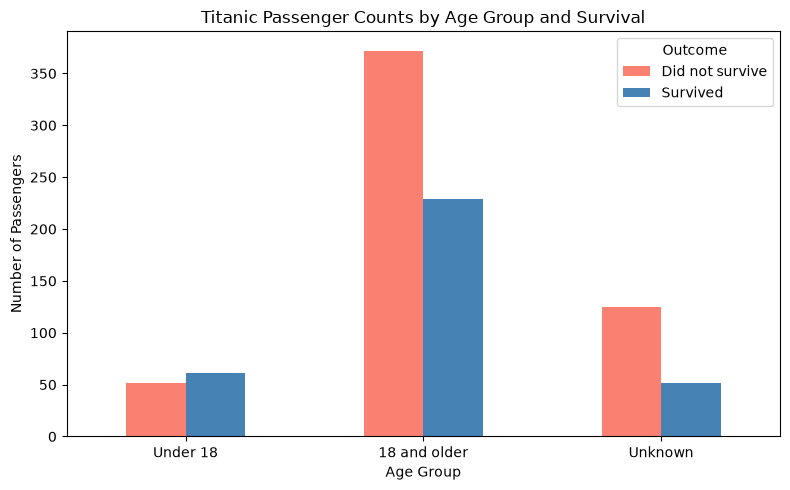

In [11]:
age_counts.rename(columns={0: "Did not survive", 1: "Survived"}).plot(
    kind="bar", color=["salmon", "steelblue"], figsize=(8, 5)
)
plt.title("Titanic Passenger Counts by Age Group and Survival")
plt.xlabel("Age Group")
plt.ylabel("Number of Passengers")
plt.xticks(rotation=0)
plt.legend(title="Outcome")
plt.tight_layout()
plt.show()


### Sex

Compare `Sex` with `Survived` using your Data-step choices.


In [13]:
sex_counts = pd.crosstab(
    titanic_df["Sex"], titanic_df["Survived"]
)
sex_counts

Survived,0,1
Sex,,
female,81,233
male,468,109


In [14]:
sex_survival_pct = sex_counts[1] / sex_counts.sum(axis=1) * 100
sex_survival_pct


Sex
female    74.203822
male      18.890815
dtype: float64

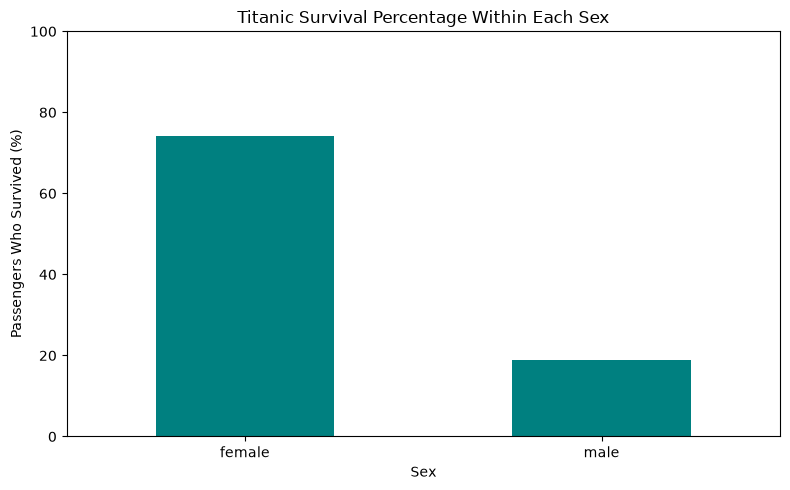

In [15]:
sex_survival_pct.plot(kind="bar", color="teal", figsize=(8, 5))
plt.title("Titanic Survival Percentage Within Each Sex")
plt.xlabel("Sex")
plt.ylabel("Passengers Who Survived (%)")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


### Passenger class

Compare `Pclass` with `Survived` using your Data-step choices.


In [16]:
class_counts = pd.crosstab(
    titanic_df["Pclass"], titanic_df["Survived"]
)
class_counts


Survived,0,1
Pclass,,
1,80,136
2,97,87
3,372,119


In [17]:
class_survival_pct = class_counts[1] / class_counts.sum(axis=1) * 100
class_survival_pct


Pclass
1    62.962963
2    47.282609
3    24.236253
dtype: float64

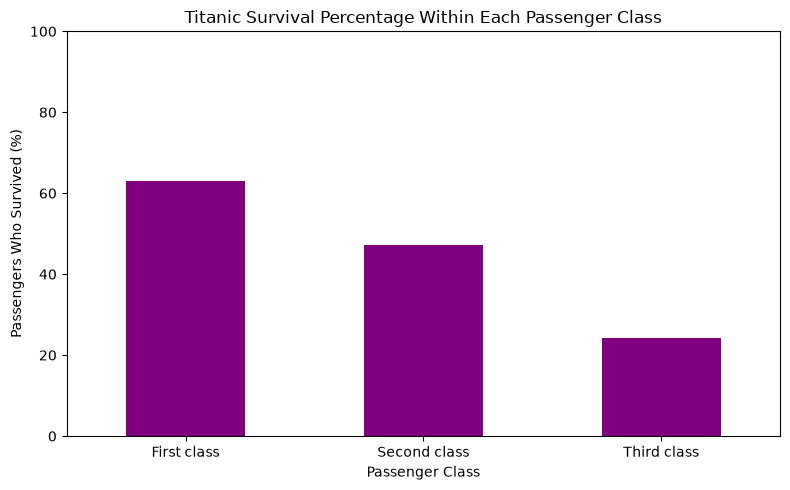

In [18]:
class_survival_pct.rename(
    index={1: "First class", 2: "Second class", 3: "Third class"}
).plot(kind="bar", color="purple", figsize=(8, 5))

plt.title("Titanic Survival Percentage Within Each Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Passengers Who Survived (%)")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


### Parents or children aboard

Compare `Parch or your derived group` with `Survived` using your Data-step choices.


In [19]:
parch_counts = pd.crosstab(
    titanic_df["parch_group"], titanic_df["Survived"]
)
parch_counts


Survived,0,1
parch_group,,
None,445,233
One or more,104,109


In [20]:
parch_survival_pct = parch_counts[1] / parch_counts.sum(axis=1) * 100
parch_survival_pct


parch_group
None           34.365782
One or more    51.173709
dtype: float64

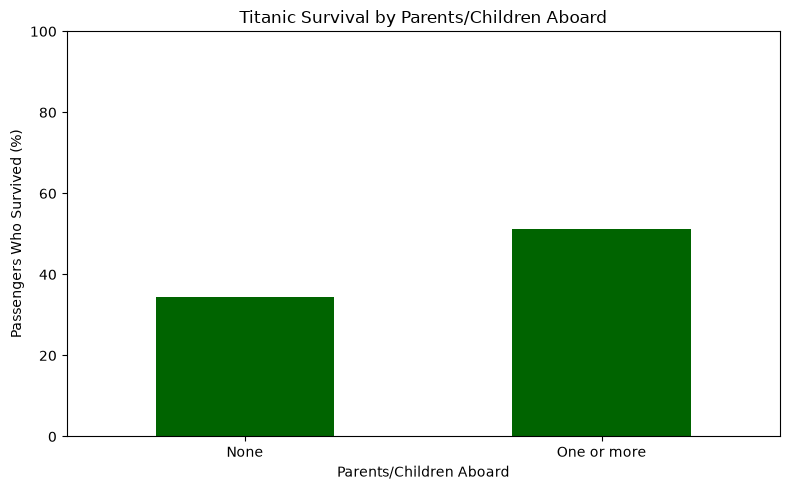

In [21]:
parch_survival_pct.plot(kind="bar", color="darkgreen", figsize=(8, 5))
plt.title("Titanic Survival by Parents/Children Aboard")
plt.xlabel("Parents/Children Aboard")
plt.ylabel("Passengers Who Survived (%)")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


### Siblings or spouse aboard

Compare `SibSp or your derived group` with `Survived` using your Data-step choices.


In [22]:
sibsp_counts = pd.crosstab(
    titanic_df["sibsp_group"], titanic_df["Survived"]
)
sibsp_counts


Survived,0,1
sibsp_group,,
None,398,210
One or more,151,132


In [23]:
sibsp_survival_pct = sibsp_counts[1] / sibsp_counts.sum(axis=1) * 100
sibsp_survival_pct


sibsp_group
None           34.539474
One or more    46.643110
dtype: float64

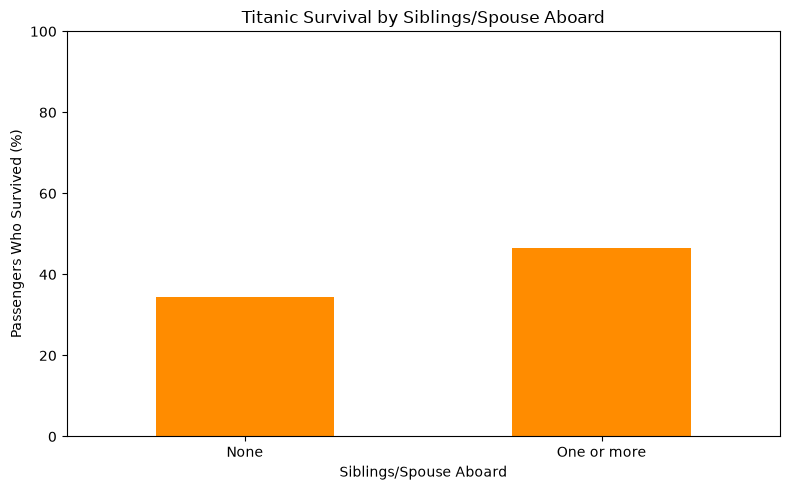

In [24]:
sibsp_survival_pct.plot(kind="bar", color="darkorange", figsize=(8, 5))
plt.title("Titanic Survival by Siblings/Spouse Aboard")
plt.xlabel("Siblings/Spouse Aboard")
plt.ylabel("Passengers Who Survived (%)")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


### Embarkation port

Compare `Embarked` with `Survived` using your Data-step choices.


In [25]:
port_counts = pd.crosstab(
    titanic_df["embarked_group"], titanic_df["Survived"]
)
port_counts


Survived,0,1
embarked_group,,
C,75,93
Q,47,30
S,427,217
Unknown,0,2


In [26]:
port_survival_pct = port_counts[1] / port_counts.sum(axis=1) * 100
port_survival_pct


embarked_group
C           55.357143
Q           38.961039
S           33.695652
Unknown    100.000000
dtype: float64

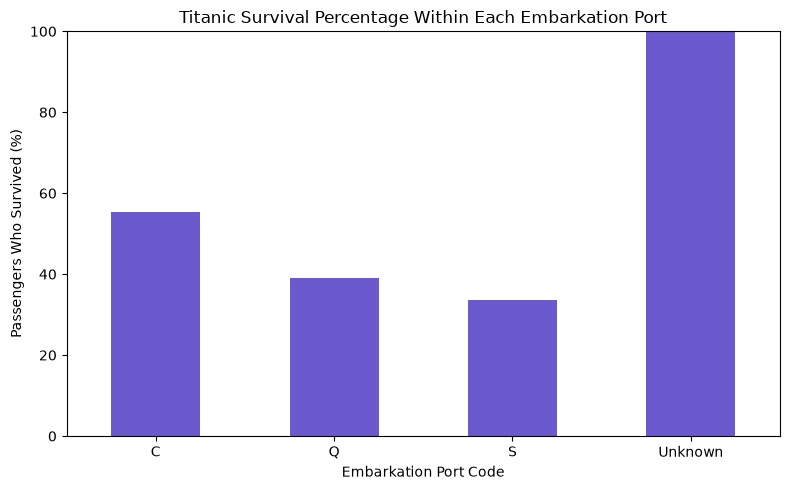

In [27]:
port_survival_pct.plot(kind="bar", color="slateblue", figsize=(8, 5))
plt.title("Titanic Survival Percentage Within Each Embarkation Port")
plt.xlabel("Embarkation Port Code")
plt.ylabel("Passengers Who Survived (%)")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [30]:
for feature, counts in {
    "Age groups": age_counts,
    "Passenger class": class_counts,
    "Parents/children aboard": parch_counts,
    "Siblings/spouse aboard": sibsp_counts,
    "Embarkation port": port_counts
}.items():
    print(feature)
    display(pd.DataFrame({
        "Survived": counts[1],
        "Group size": counts.sum(axis=1),
        "Survival percentage": (
            counts[1] / counts.sum(axis=1) * 100
        ).round(2)
    }))

Age groups


,Survived,Group size,Survival percentage
age_group,,,
Under 18,61,113,53.98
18 and older,229,601,38.10
Unknown,52,177,29.38


Passenger class


,Survived,Group size,Survival percentage
Pclass,,,
1,136,216,62.96
2,87,184,47.28
3,119,491,24.24


Parents/children aboard


,Survived,Group size,Survival percentage
parch_group,,,
None,233,678,34.37
One or more,109,213,51.17


Siblings/spouse aboard


,Survived,Group size,Survival percentage
sibsp_group,,,
None,210,608,34.54
One or more,132,283,46.64


Embarkation port


,Survived,Group size,Survival percentage
embarked_group,,,
C,93,168,55.36
Q,30,77,38.96
S,217,644,33.70
Unknown,2,2,100.00


### Summarize the evidence

Record the highest- and lowest-survival categories for each feature. Include percentages and group sizes; mention ties or very small groups that affect interpretation.


| Feature | Highest-survival category, percentage, and group size | Lowest-survival category, percentage, and group size |
| --- | --- | --- |
| Sex  | Female: 74.2% survived (233 of 314 passengers). | Male: 18.9% survived (109 of 577 passengers). |
| Age groups | 	Under 18: 53.98% (61 of 113) | 	Unknown: 29.38% (52 of 177). Among known ages, adults: 38.10% (229 of 601) |
| Passenger class | 	First class: 62.96% (136 of 216) | 	Third class: 24.24% (119 of 491) |
| Parents or children aboard | One or more: 51.17% (109 of 213) | 	None: 34.37% (233 of 678) |
| Siblings or spouse aboard | 	One or more: 46.64% (132 of 283) | 	None: 34.54% (210 of 608) |
| Embarkation port | 	Unknown: 100% (2 of 2), a very small group. Among known ports, C: 55.36% (93 of 168) | S: 33.70% (217 of 644) |


**Using the age comparison, interpret one joint percentage and one conditional percentage. What denominator does each use, and which figure answers the survival-likelihood question more clearly?**

Your answer:Passengers under 18 who survived represent approximately 6.85% of all 891 passengers (61 ÷ 891 × 100). This is a joint percentage: it describes passengers who were both under 18 and survived.

Among the 113 passengers under 18, 53.98% survived (61 ÷ 113 × 100). This is a conditional percentage, using only passengers under 18 as the denominator. The conditional-percentage chart answers the survival-likelihood question more clearly because it accounts for differences in age-group sizes.


## Step 4: Check

Check the meaning of your combined evidence, rather than repeating the initial row count or missing-value inspection.

- Compare each age group's minimum and maximum known ages with your declared boundaries, including exact cutoffs and unknown ages.
- If you collapsed travel-companion categories, cross-tab the original counts against your group labels.
- Check that percentages use all passengers in the relevant group, not just survivors. Compare the direction of the percentages with the count tables.
- Identify sparse groups or implausible values that deserve caution.


In [28]:
display(
    titanic_df.groupby("age_group")["Age"].agg(["count", "min", "max"])
)

display(
    titanic_df.loc[
        titanic_df["Age"].isna(), "age_group"
    ].value_counts()
)

display(
    titanic_df.loc[
        titanic_df["Age"] == 18, ["Age", "age_group"]
    ].head()
)


,count,min,max
age_group,,,
18 and older,601,18.00,80.0
Under 18,113,0.42,17.0
Unknown,0,NaN,NaN


age_group
Unknown    177
Name: count, dtype: int64

,Age,age_group
38,18.0,18 and older
49,18.0,18 and older
144,18.0,18 and older
175,18.0,18 and older
204,18.0,18 and older


In [29]:
display(pd.crosstab(titanic_df["Parch"], titanic_df["parch_group"]))
display(pd.crosstab(titanic_df["SibSp"], titanic_df["sibsp_group"]))

display(pd.DataFrame({
    "All passengers in age group": age_counts.sum(axis=1),
    "Survivors": age_counts[1],
    "Survival percentage": age_survival_pct
}))


parch_group,None,One or more
Parch,,
0,678,0
1,0,118
2,0,80
3,0,5
4,0,4
5,0,5
6,0,1


sibsp_group,None,One or more
SibSp,,
0,608,0
1,0,209
2,0,28
3,0,16
4,0,18
5,0,5
8,0,7


,All passengers in age group,Survivors,Survival percentage
age_group,,,
Under 18,113,61,53.982301
18 and older,601,229,38.103161
Unknown,177,52,29.378531


**Do the age boundaries, category mappings, and denominators match your intentions? What would make you suspicious, and did you find or correct any issues? Which small groups limit interpretation?**

Your answer:Passengers under 18 who survived represent approximately 6.85% of all 891 passengers (61 ÷ 891 × 100). This is a joint percentage: it describes passengers who were both under 18 and survived.

Among the 113 passengers under 18, 53.98% survived (61 ÷ 113 × 100). This is a conditional percentage, using only passengers under 18 as the denominator. The conditional-percentage chart answers the survival-likelihood question more clearly because it accounts for differences in age-group sizes.


## Step 5: Conclusion

Use the combined evidence to develop the two profiles, find matching passengers, and connect them to historical biographies.


### Build your two character profiles

Combine the evidence into a “most likely to survive” profile and a “least likely to survive” profile. Include all six elements. Cite the relevant group percentage and size for each choice. Do not multiply separate feature percentages to produce an individual survival probability: the features may be related, and separate comparisons do not establish the survival rate for their combination.


| Profile element | Most likely profile: category and evidence | Least likely profile: category and evidence |
| --- | --- | --- |
| Sex (example) | Female: 74.2% survived (233 of 314 passengers). | Male: 18.9% survived (109 of 577 passengers). |
| Age groups | Under 18: 53.98% (61 of 113) | 18 and older: 38.10% (229 of 601) |
| Passenger class | First class: 62.96% (136 of 216) | Third class: 24.24% (119 of 491) |
| Parents or children aboard |One or more: 51.17% (109 of 213)  | None: 34.37% (233 of 678) |
| Siblings or spouse aboard | One or more: 46.64% (132 of 283) | None: 34.54% (210 of 608) |
| Embarkation port | 	C: 55.36% (93 of 168) | 	S: 33.70% (217 of 644) |


**Write a short character description for each profile. Explain any tradeoffs where the evidence does not point to a single obvious combination.**

Your answer:My higher-survival profile is a female passenger under 18, traveling in first class, with at least one parent/child and at least one sibling/spouse aboard, who embarked at C. My lower-survival profile is an adult male traveling in third class, with neither type of family companion recorded, who embarked at S.

I used known-age groups and known ports rather than missing-information categories. These choices combine patterns from separate comparisons; they do not establish a survival probability for the complete profile or guarantee any individual’s outcome.


### Find real passengers who fit

Use Boolean conditions with `.loc` to find passengers matching each profile across all six elements. Save the results as `most_likely_df` and `least_likely_df`, and display their names and the features used to match them. **Do not filter on `Survived` to build these lists**: an actual outcome is not a profile characteristic.

If a list is empty, explain which combination has no matching record, then revise and justify your profile transparently using the evidence. Keep all six elements in your revised profile, update the profile table, and rerun the filter. Do not silently drop a condition or invent a passenger. You need at least one matching person in each list.


In [35]:
profile_columns = [
    "Name", "Sex", "Age", "age_group", "Pclass",
    "Parch", "SibSp", "Embarked"
]

most_likely_df = titanic_df.loc[
    (titanic_df["Sex"] == "female")
    & (titanic_df["age_group"] == "18 and older")
    & (titanic_df["Pclass"] == 1)
    & (titanic_df["Parch"] > 0)
    & (titanic_df["SibSp"] > 0)
    & (titanic_df["Embarked"] == "C")
].copy()

display(most_likely_df[person_columns])


,PassengerId,Name,Age,Sex,Pclass,Parch,SibSp,Embarked
311,312,"Ryerson, Miss. Emily Borie",18.0,female,1,2,2,C
319,320,"Spedden, Mrs. Frederic Oakley (Margaretta Corn...",40.0,female,1,1,1,C
581,582,"Thayer, Mrs. John Borland (Marian Longstreth M...",39.0,female,1,1,1,C
742,743,"Ryerson, Miss. Susan Parker ""Suzette""",21.0,female,1,2,2,C
835,836,"Compton, Miss. Sara Rebecca",39.0,female,1,1,1,C


In [32]:
least_likely_df = titanic_df.loc[
    (titanic_df["Sex"] == "male")
    & (titanic_df["age_group"] == "18 and older")
    & (titanic_df["Pclass"] == 3)
    & (titanic_df["Parch"] == 0)
    & (titanic_df["SibSp"] == 0)
    & (titanic_df["Embarked"] == "S")
].copy()

display(least_likely_df[profile_columns])


,Name,Sex,Age,age_group,Pclass,Parch,SibSp,Embarked
4,"Allen, Mr. William Henry",male,35.0,18 and older,3,0,0,S
12,"Saundercock, Mr. William Henry",male,20.0,18 and older,3,0,0,S
37,"Cann, Mr. Ernest Charles",male,21.0,18 and older,3,0,0,S
51,"Nosworthy, Mr. Richard Cater",male,21.0,18 and older,3,0,0,S
67,"Crease, Mr. Ernest James",male,19.0,18 and older,3,0,0,S
...,...,...,...,...,...,...,...,...
873,"Vander Cruyssen, Mr. Victor",male,47.0,18 and older,3,0,0,S
876,"Gustafsson, Mr. Alfred Ossian",male,20.0,18 and older,3,0,0,S
877,"Petroff, Mr. Nedelio",male,19.0,18 and older,3,0,0,S
881,"Markun, Mr. Johann",male,33.0,18 and older,3,0,0,S


**How do your filters match the six profile choices? Document any revisions needed to obtain real matches.**

Your answer:My lower-survival filter applies all six conditions together using AND: male, age 18 or older, passenger class 3, Parch equal to 0, SibSp equal to 0, and Embarked equal to S. It returned 151 matching passengers, so no revision was needed for this profile. I did not filter on survival outcome.


In [33]:
person_columns = [
    "PassengerId", "Name", "Age", "Sex",
    "Pclass", "Parch", "SibSp", "Embarked"
]

print("Higher-survival profile matches:")
display(most_likely_df[person_columns])

print("First five lower-survival profile matches:")
display(least_likely_df[person_columns].head())

Higher-survival profile matches:


,PassengerId,Name,Age,Sex,Pclass,Parch,SibSp,Embarked


First five lower-survival profile matches:


,PassengerId,Name,Age,Sex,Pclass,Parch,SibSp,Embarked
4,5,"Allen, Mr. William Henry",35.0,male,3,0,0,S
12,13,"Saundercock, Mr. William Henry",20.0,male,3,0,0,S
37,38,"Cann, Mr. Ernest Charles",21.0,male,3,0,0,S
51,52,"Nosworthy, Mr. Richard Cater",21.0,male,3,0,0,S
67,68,"Crease, Mr. Ernest James",19.0,male,3,0,0,S


In [34]:
high_profile_candidates_df = titanic_df.loc[
    (titanic_df["Sex"] == "female")
    & (titanic_df["Age"].notna())
    & (titanic_df["Pclass"] == 1)
    & (titanic_df["Parch"] > 0)
    & (titanic_df["SibSp"] > 0)
    & (titanic_df["Embarked"] == "C")
].copy()

display(high_profile_candidates_df[
    ["PassengerId", "Name", "Age", "age_group",
     "Sex", "Pclass", "Parch", "SibSp", "Embarked"]
])

,PassengerId,Name,Age,age_group,Sex,Pclass,Parch,SibSp,Embarked
311,312,"Ryerson, Miss. Emily Borie",18.0,18 and older,female,1,2,2,C
319,320,"Spedden, Mrs. Frederic Oakley (Margaretta Corn...",40.0,18 and older,female,1,1,1,C
581,582,"Thayer, Mrs. John Borland (Marian Longstreth M...",39.0,18 and older,female,1,1,1,C
742,743,"Ryerson, Miss. Susan Parker ""Suzette""",21.0,18 and older,female,1,2,2,C
835,836,"Compton, Miss. Sara Rebecca",39.0,18 and older,female,1,1,1,C


### Connect the records to people

Choose one person from `most_likely_df` and one from `least_likely_df`. Find each person on [Encyclopedia Titanica](https://www.encyclopedia-titanica.org/) using its passenger lists or biography search. Check identifying details to make sure you found the same person; names can have spelling variations.

For each person, select at least one interesting fact from the biography beyond the values already listed in your dataset. Describe it in your own words and link directly to the biography. Do not substitute an uncited fact or just restate survival status.


**Who did you choose from your “most likely to survive” list? Give the dataset name and PassengerId, explain how you matched the biography, describe an interesting fact, and provide the direct Encyclopedia Titanica biography URL.**

Your answer:I chose “Ryerson, Miss. Emily Borie,” PassengerId 312. I matched her name, age of 18, first-class status, and embarkation at Cherbourg (C) with the biography of Emily Borie Ryerson, rather than her similarly named mother. An interesting fact is that her family cut short their European holiday after learning that her brother Arthur had died in an automobile accident.

Biography: https://www.encyclopedia-titanica.org/titanic-survivor/emily-borie-ryerson.html


**Who did you choose from your “least likely to survive” list? Give the dataset name and PassengerId, explain how you matched the biography, describe an interesting fact, and provide the direct Encyclopedia Titanica biography URL.**

Your answer:I chose “Allen, Mr. William Henry,” PassengerId 5. I matched his full name and third-class status with the biography of William Henry Allen. His ticket number, 373450, also matches the dataset preview. An interesting fact is that a suitcase recovered from the wreck in 2000 contained clothing marked with his name. There is an age discrepancy: the dataset records him as 35, while the biography gives a birth year of 1873, making him about 39 in 1912. I retained the dataset’s age for the analysis.

Biography: https://www.encyclopedia-titanica.org/titanic-victim/william-henry-allen.html


After choosing the people, compare their recorded survival outcomes with their profiles. A passenger can contradict a group tendency. If the biography conflicts with this dataset, report the disagreement and what the sources say rather than silently changing the data.


In [36]:

selected_people_df = titanic_df.loc[
    titanic_df["PassengerId"].isin([312, 5]),
    ["PassengerId", "Name", "Age", "Sex", "Pclass", "Survived"]
]

selected_people_df

,PassengerId,Name,Age,Sex,Pclass,Survived
4,5,"Allen, Mr. William Henry",35.0,male,3,0
311,312,"Ryerson, Miss. Emily Borie",18.0,female,1,1


**Did each person's actual outcome align with the profile label? What does this show about using group patterns to describe individuals? Note any discrepancies with the biographies.**

Your answer:Both outcomes aligned with the profile labels: Emily Borie Ryerson survived (Survived = 1), while William Henry Allen did not (Survived = 0). However, two matching examples do not prove that these profiles predict every individual’s outcome. Allen’s age differs between sources: the dataset records 35, while his biography’s birth year places him around 39. Both ages put him in the adult category, so this discrepancy does not change his profile match.


### Final recommendation to the director


**Recommend the two characters using numerical evidence and their biographical facts. How do your completed profiles compare with your initial predictions? Explain any tradeoffs or revisions.**

Your answer:I recommend Emily Borie Ryerson and William Henry Allen as contrasting characters. Emily matches the revised higher-survival profile: female, adult, first class, both types of family companion aboard, and embarkation at C. Female passengers had 74.20% survival and first-class passengers had 62.96% survival. Her family’s interrupted European holiday following her brother’s death provides biographical context.

Allen matches the lower-survival profile: an adult male in third class, with neither type of family companion recorded, embarking at S. Male passengers had 18.89% survival and third-class passengers had 24.24% survival. The recovery of his suitcase in 2000 provides a personal connection to the wreck.

The higher-survival profile originally specified under 18, but that six-condition combination had no matches. I revised it to adults and obtained five matches, accepting the lower adult survival rate of 38.10% compared with 53.98% for passengers under 18. The lower-survival profile required no revision.


## Step 6: Limitation


**What should the director avoid concluding? Discuss why separate feature comparisons do not establish an individual survival probability or causation, and address relevant limitations such as small groups, missing ages, category choices, or uncertain historical records.**

Your answer:The director should avoid treating these profiles as individual survival probabilities or evidence of causation. The separate feature percentages cannot be multiplied because age, sex, class, family companions, and embarkation port may be related. We have not calculated survival rates for the complete combinations.

Results also depend on the age cutoff and the decision to combine family counts into “None” and “One or more.” There are 177 missing ages, and the unknown-port category contains only two passengers, making its 100% survival rate unreliable for building a profile. The revised higher-survival combination has only five matches. Historical records can disagree, as shown by Allen’s age, and this dataset does not necessarily represent everyone aboard the Titanic.


## AI-use reflection


**Did you use AI? If so, describe one suggestion you checked and accepted, modified, or rejected. If not, state that you did not use it.**

Your answer:
AI was used to rewrite my written responses to correct punctuation, grammer and increas details on some of the answers
AI was also used when i got tangled up in the end of the asignment mainly sue to time running out for me to complete the assignment so i used it to help me write the code to generate the %s i needed to continue. I accepted the code for the %s and modified to written response after they were re-written. I rejected AI generated code following the answer to the %s


## Submission checklist

- Complete one six-step workflow with an initial prediction and evidence for all six profile elements.
- Justify age boundaries and missing-age handling; use passenger class, not fare.
- Include a labeled visualization for every profile element and the age count-versus-percentage comparison.
- Support both complete profiles with group percentages and sizes.
- Display both matching-passenger lists and select one real person from each.
- Include an interesting fact and direct Encyclopedia Titanica biography link for each selected person.
- Complete the combined conclusion, limitation, and AI-use reflection.
- Restart the kernel and run all cells in order; check that claims match the output.
